In [1]:
from dotenv import load_dotenv
from job_match_hunter.data_layer.database import supabase_backend
import pandas as pd
import matplotlib.pyplot as plt

load_dotenv()

response = (
    supabase_backend.table("model_runs")
    .select("model, prompt, input, score, latency, cost")
    .is_("error", "null")
    .not_.is_("score", "null")
    .eq("experiment_type", "JD parsing")
    .eq("finish_reason", "stop")
    .execute()
)

rows = response.data

df = pd.DataFrame(rows)

In [2]:
prompts = sorted(list(set(df["prompt"])))
inputs = sorted(list(set(df["input"])))
prompts, inputs

(['jd_01_persona.txt', 'jd_02_persona.txt', 'jd_03_persona_fewshot.txt'],
 ['jd_01_easy.txt', 'jd_02_medium.txt', 'jd_03_hard.txt'])

# Score

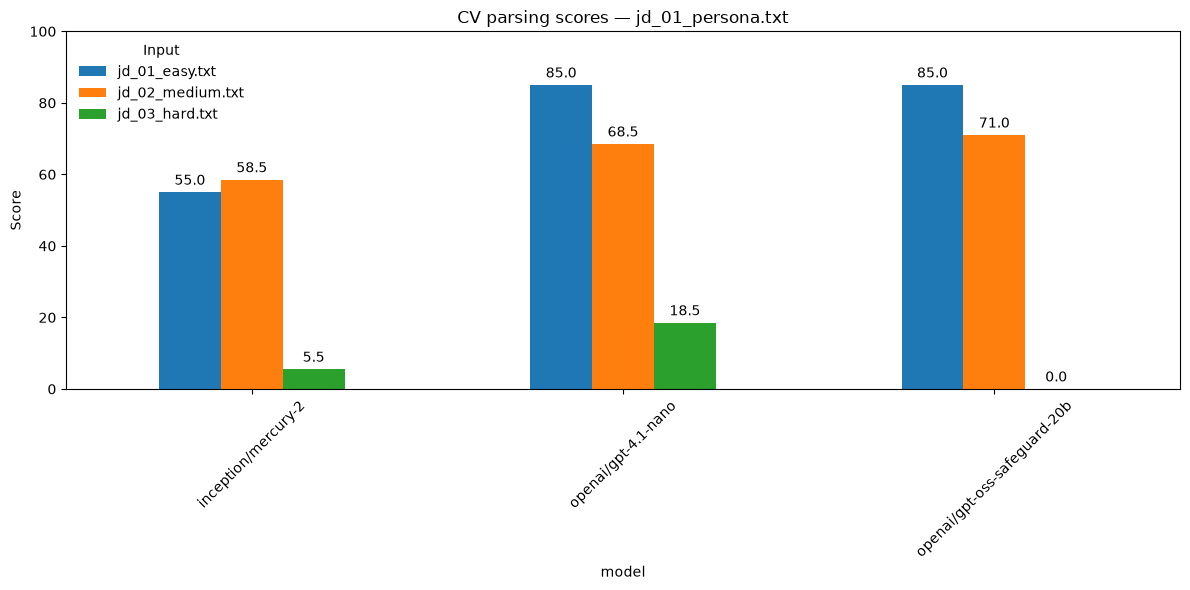

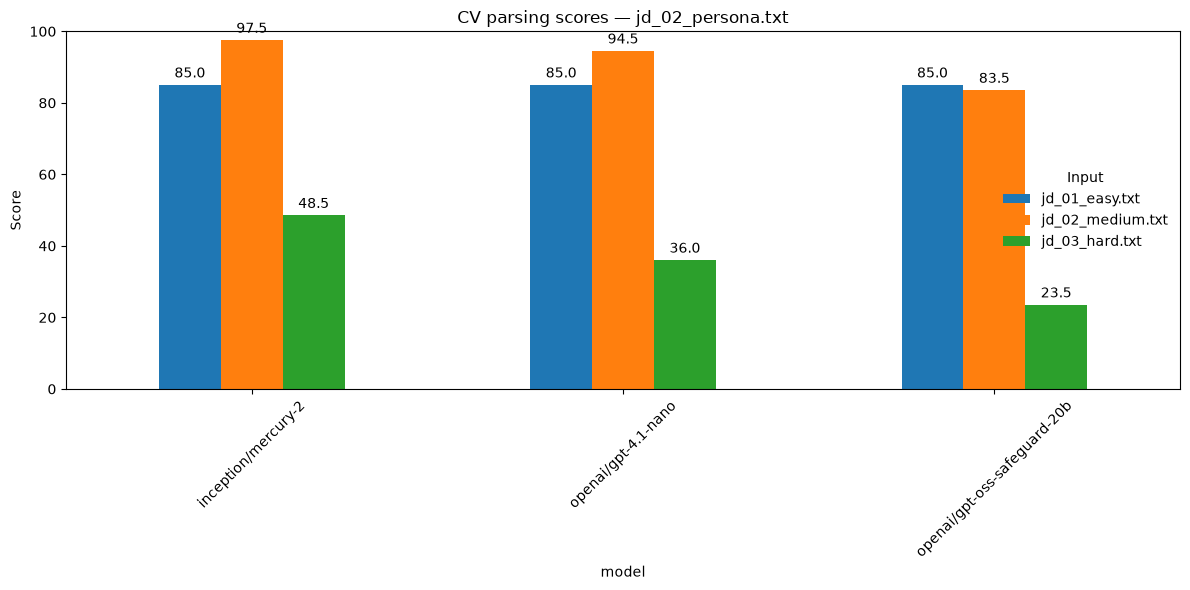

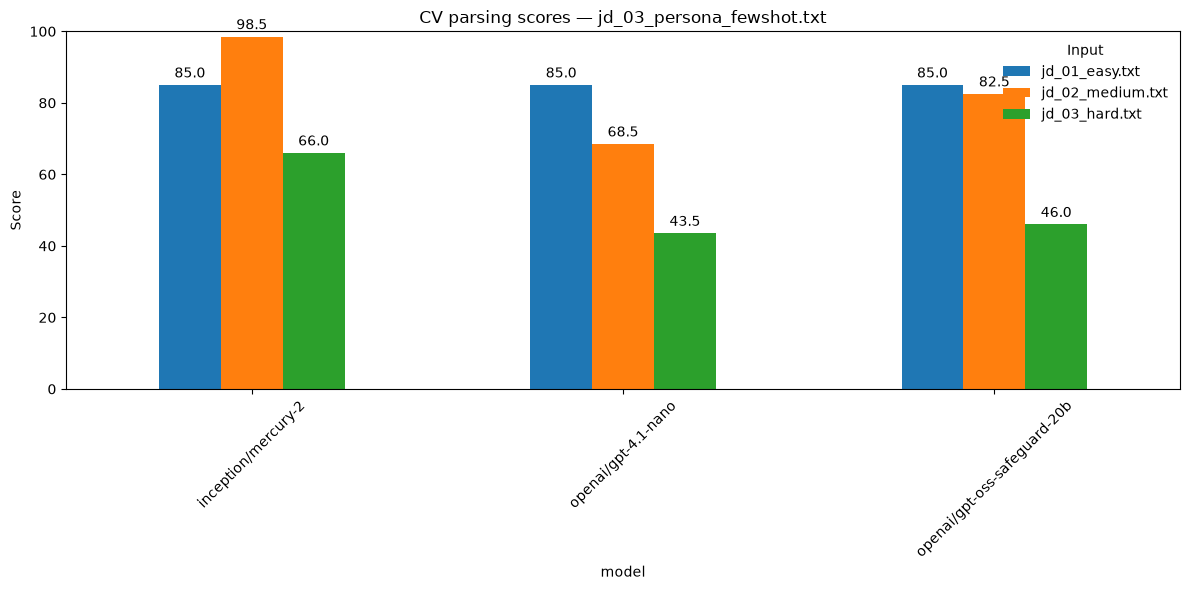

In [3]:
for prompt in prompts:
    # filter df based on prompt type
    prompt_df = df[df["prompt"] == prompt]
    # reshape df so each model is a row and each CV input becomes a separate bar
    plot_df = prompt_df.pivot(
        index="model",
        columns="input",
        values="score",
    )
    # plotting
    ax = plot_df.plot(
        kind="bar",
        figsize=(12, 6),
    )
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.1f",
            padding=3,
        )

    ax.set_ylabel("Score")
    ax.set_title(f"CV parsing scores — {prompt}")
    ax.legend(title="Input", framealpha=0)
    ax.tick_params(axis="x", rotation=45)
    ax.set_ylim(0, 100)

    plt.tight_layout()
    plt.show()
    

# Latency

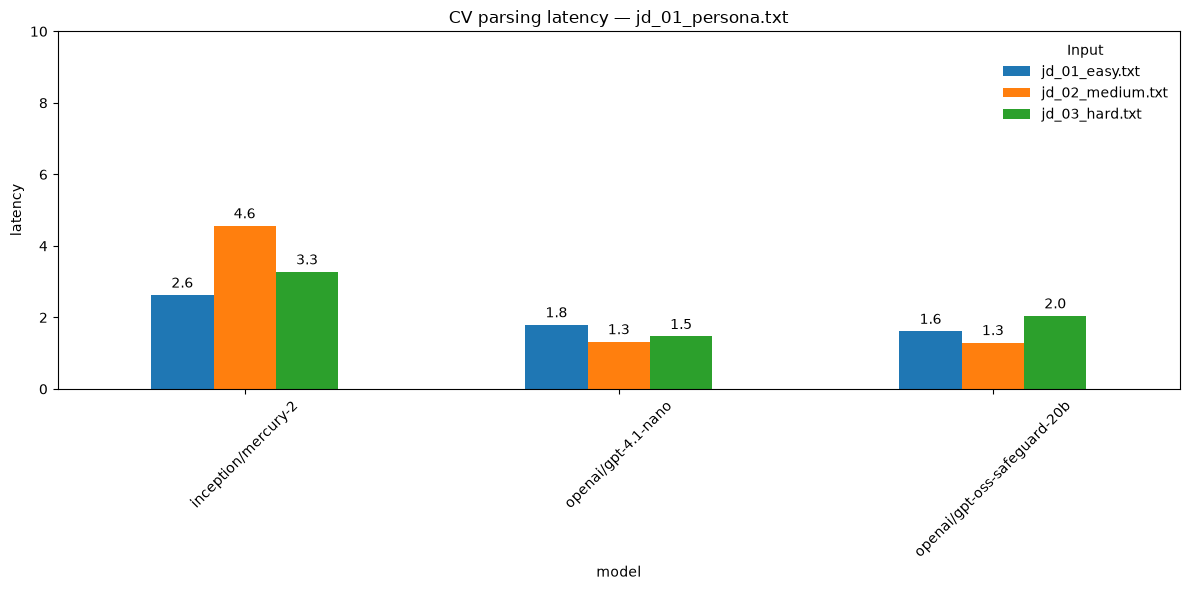

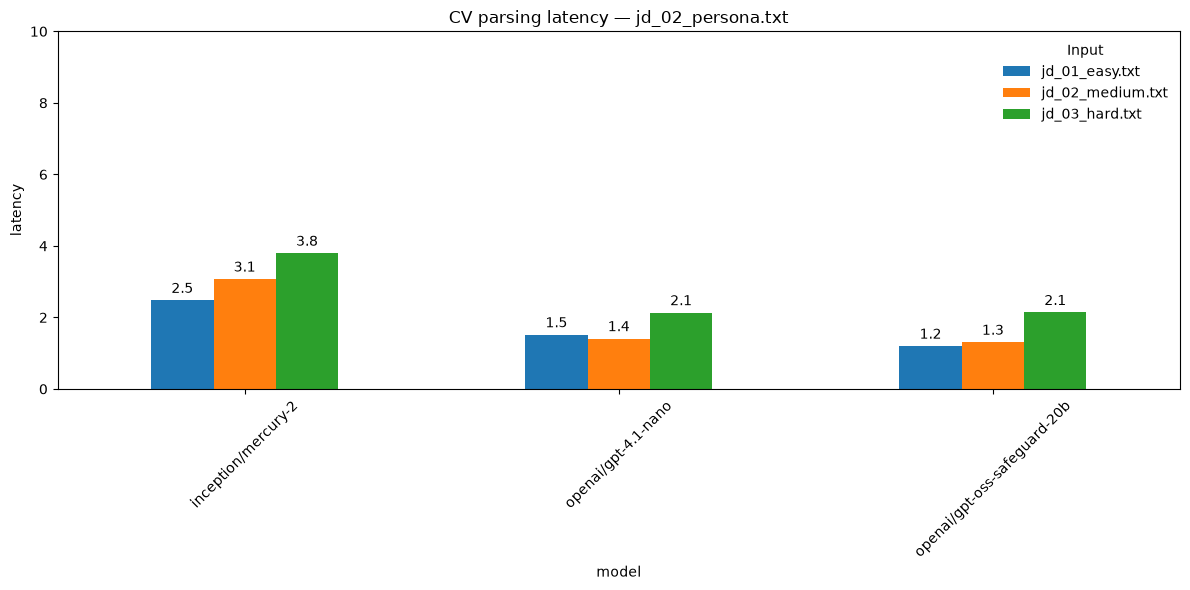

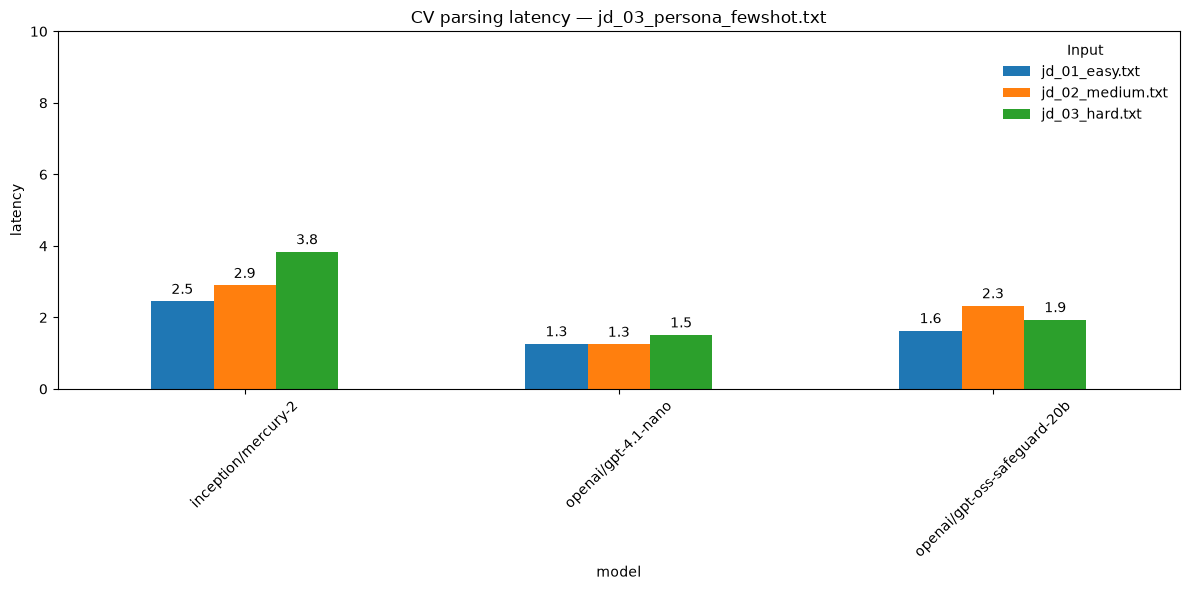

In [4]:
for prompt in prompts:
    # filter df based on prompt type
    prompt_df = df[df["prompt"] == prompt]
    # reshape df so each model is a row and each CV input becomes a separate bar
    plot_df = prompt_df.pivot(
        index="model",
        columns="input",
        values="latency",
    )
    # plotting
    ax = plot_df.plot(
        kind="bar",
        figsize=(12, 6),
    )
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.1f",
            padding=3,
        )

    ax.set_ylabel("latency")
    ax.set_title(f"CV parsing latency — {prompt}")
    ax.legend(title="Input", framealpha=0)
    ax.tick_params(axis="x", rotation=45)
    ax.set_ylim(0, 10)

    plt.tight_layout()
    plt.show()
    

# Cost

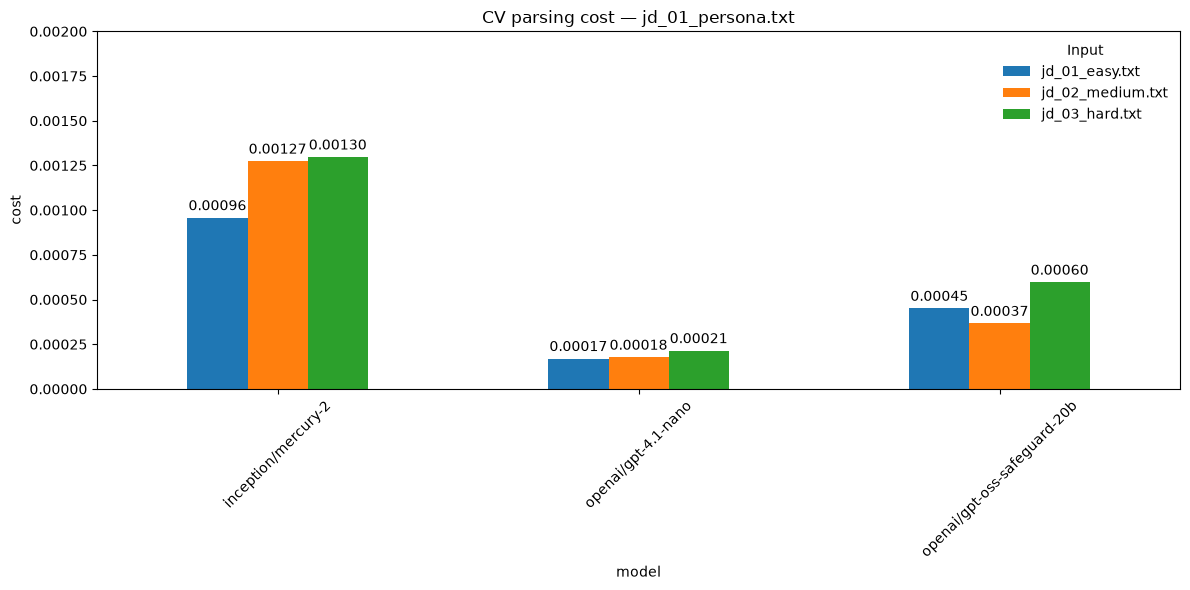

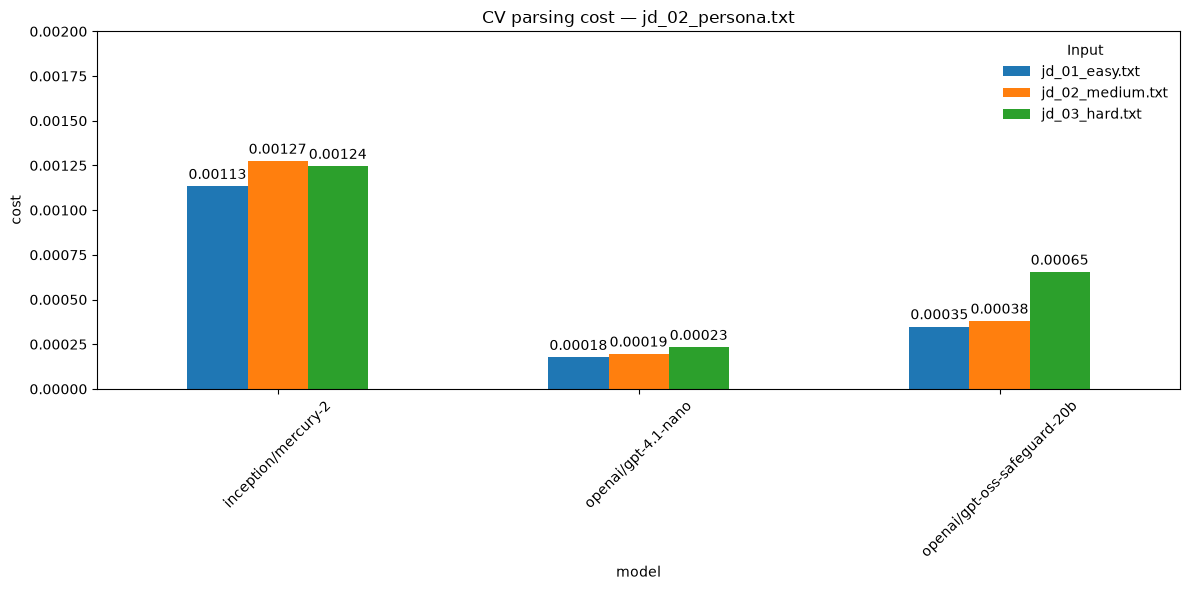

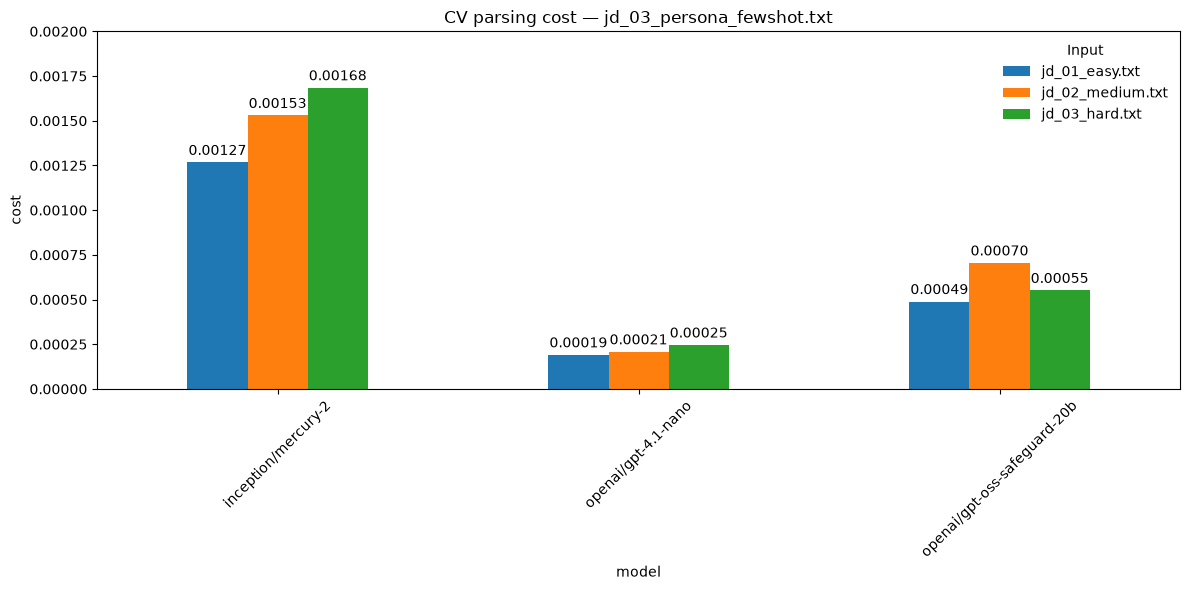

In [5]:
for prompt in prompts:
    # filter df based on prompt type
    prompt_df = df[df["prompt"] == prompt]
    # reshape df so each model is a row and each CV input becomes a separate bar
    plot_df = prompt_df.pivot(
        index="model",
        columns="input",
        values="cost",
    )
    # plotting
    ax = plot_df.plot(
        kind="bar",
        figsize=(12, 6),
    )
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.5f",
            padding=3,
        )

    ax.set_ylabel("cost")
    ax.set_title(f"CV parsing cost — {prompt}")
    ax.legend(title="Input", framealpha=0)
    ax.tick_params(axis="x", rotation=45)
    ax.set_ylim(0, 0.002)

    plt.tight_layout()
    plt.show()
    